<a href="https://colab.research.google.com/github/isaaccg88/PredictiveMaintenance-AI-Activity4/blob/main/notebooks/PredictiveMaintenance_Actividad4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Configuración del entorno de ejecución

### Objetivo
Preparar y verificar el entorno de prototipado en Google Colab para la implementación de modelos preentrenados de Hugging Face aplicados al mantenimiento predictivo industrial.

### Procedimiento
Se utiliza Python y la biblioteca PyTorch para identificar las versiones del entorno y comprobar la disponibilidad de aceleración mediante GPU.

La verificación contempla:
- Versión de Python.
- Versión de PyTorch.
- Disponibilidad de CUDA.
- Modelo de GPU asignado por Google Colab.

### Resultado obtenido
- Python: 3.13.15.
- PyTorch: 2.11.0+cu130.
- GPU disponible: Sí.
- Dispositivo: NVIDIA Tesla T4.

### Interpretación técnica
Se confirmó la disponibilidad de aceleración por GPU, necesaria para evaluar modelos fundacionales basados en arquitecturas Transformer.

La configuración es adecuada para comenzar las pruebas de compatibilidad, aunque la capacidad de memoria, la latencia y el consumo de recursos deberán verificarse individualmente para cada modelo.

### Relación con la rúbrica
Contribuye al criterio 2: implementación y prototipado en Google Colab con GPU, documentación del entorno y reproducibilidad.



In [ ]:
import torch
import sys

print("Versión de Python:", sys.version.split()[0])
print("Versión de PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU detectada:", torch.cuda.get_device_name(0))
else:
    print("No se detectó GPU.")

Versión de Python: 3.13.15
Versión de PyTorch: 2.11.0+cu130
GPU disponible: True
GPU detectada: Tesla T4


## 2. Adquisición y exploración inicial del dataset

### Objetivo
Obtener un conjunto de datos representativo de condiciones operativas industriales para evaluar modelos preentrenados en una tarea de clasificación binaria de fallas.

### Fuente de información
**Dataset:** AI4I 2020 Predictive Maintenance Dataset  
**Repositorio:** UCI Machine Learning Repository  
**Identificador UCI:** 601  
**Enlace:** https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

El dataset contiene datos sintéticos que simulan condiciones de funcionamiento de maquinaria industrial.

### Variables predictoras
1. Type: categoría de producto.
2. Air temperature: temperatura del aire.
3. Process temperature: temperatura del proceso.
4. Rotational speed: velocidad de rotación.
5. Torque: torque aplicado.
6. Tool wear: desgaste de herramienta.

### Variable objetivo
**Machine failure**
- 0: operación sin falla.
- 1: registro con falla.

### Resultados obtenidos
- Registros totales: 10,000.
- Variables predictoras: 6.
- Registros sin falla: 9,661 (96.61%).
- Registros con falla: 339 (3.39%).

### Interpretación
El dataset presenta un desbalance importante entre las clases.

Un clasificador que predijera siempre ausencia de falla alcanzaría 96.61% de accuracy, pero no identificaría ninguna falla.

Por este motivo, se utilizarán precision, recall, F1-score y matrices de confusión, prestando especial atención a la identificación de fallas y a los falsos negativos.

### Limitación del caso de uso
La etiqueta identifica condiciones de falla en los registros disponibles, pero no incorpora un horizonte temporal futuro.

Por tanto, el experimento evalúa la clasificación de estados de falla como componente de una solución de mantenimiento predictivo, sin demostrar todavía anticipación temporal de fallas.

### Relación con la rúbrica
Contribuye a la selección y contextualización del problema, descripción del dataset y fundamentación de las métricas de evaluación.

In [1]:
# Dataset: AI4I 2020 Predictive Maintenance

%pip -q install ucimlrepo

import pandas as pd
from ucimlrepo import fetch_ucirepo

# Descargar el dataset original
dataset = fetch_ucirepo(id=601)

# Separar variables predictoras y objetivo
X = dataset.data.features.copy()
y = dataset.data.targets["Machine failure"].astype(int)

# Construir tabla para exploración
df = X.copy()
df["Machine failure"] = y

print("Dataset cargado correctamente")
print("Total de registros:", len(df))
print("Variables predictoras:", X.shape[1])
print("\nColumnas disponibles:")
print(df.columns.tolist())

print("\nDistribución de fallas (0 = No, 1 = Sí):")
print(y.value_counts().sort_index())

print("\nPrimeros cinco registros:")
display(df.head())


Dataset cargado correctamente
Total de registros: 10000
Variables predictoras: 6

Columnas disponibles:
['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure']

Distribución de fallas (0 = No, 1 = Sí):
Machine failure
0    9661
1     339
Name: count, dtype: int64

Primeros cinco registros:


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 3. Validación de calidad y partición estratificada

### Objetivo
Comprobar la integridad del dataset y establecer un protocolo experimental reproducible para comparar al menos tres modelos preentrenados bajo condiciones equivalentes.

### Validación de calidad
Se revisó la presencia de valores faltantes en todas las variables predictoras y en la variable objetivo.

**Resultado:** no se identificaron valores faltantes.

### Estrategia de partición
Se aplicó una separación estratificada con `random_state=42`:

| Conjunto | Registros | Fallas | % fallas |
|---|---:|---:|---:|
| Entrenamiento | 7,000 | 237 | 3.39% |
| Validación | 1,500 | 51 | 3.40% |
| Prueba | 1,500 | 51 | 3.40% |

### Justificación metodológica
La estratificación conserva la proporción de fallas, lo que resulta especialmente importante debido al desbalance del dataset.

Cada conjunto tiene una finalidad diferenciada:

- **Entrenamiento:** ejemplos etiquetados que utilizarán los modelos para adaptar sus predicciones al problema.
- **Validación:** selección de configuraciones, análisis preliminar y posibles ajustes de umbral.
- **Prueba:** evaluación final del desempeño sobre registros no utilizados en las decisiones de ajuste.

Los tres modelos utilizarán particiones idénticas.

### Control de reproducibilidad
Se utiliza una semilla fija (`SEED=42`) para reproducir la partición.

Las transformaciones que requieran estimar parámetros se ajustarán únicamente con los datos de entrenamiento, evitando fugas de información desde validación y prueba.

### Limitación
La partición es aleatoria y estratificada, adecuada para esta evaluación tabular académica. No representa una validación temporal ni garantiza generalización a maquinaria industrial real.

### Relación con la rúbrica
Contribuye a los criterios 2 y 3: prototipado reproducible, aplicación correcta de métricas y comparación metodológicamente consistente.

Valores faltantes por columna:
Type                   0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Machine failure        0
dtype: int64

Distribución de las clases:


,count
Machine failure,
Sin falla,9661
Con falla,339



Distribución de los conjuntos:


,Conjunto,Registros,Fallas,Porcentaje de fallas
0,Entrenamiento,7000,237,3.39
1,Validación,1500,51,3.40
2,Prueba,1500,51,3.40


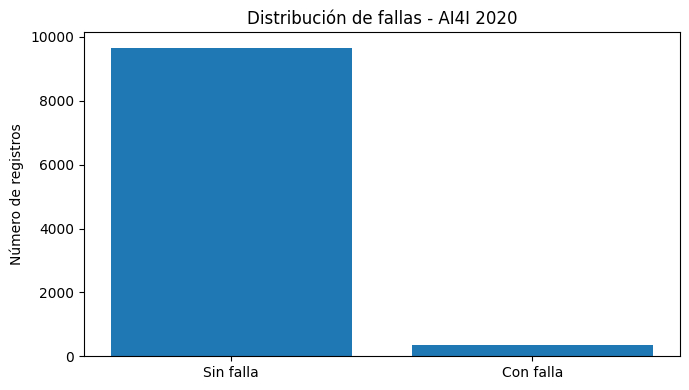

In [2]:
# ACTIVIDAD 3 - ANÁLISIS Y PARTICIÓN DEL DATASET

from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

# Revisar calidad inicial
print("Valores faltantes por columna:")
print(df.isnull().sum())

print("\nDistribución de las clases:")
conteo = y.value_counts().sort_index()
display(conteo.rename(index={0: "Sin falla", 1: "Con falla"}))

# División estratificada: 70% / 15% / 15%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    random_state=SEED, stratify=y_temp
)

resumen = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "Registros": [len(y_train), len(y_val), len(y_test)],
    "Fallas": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "Porcentaje de fallas": [
        round(100 * serie.mean(), 2)
        for serie in [y_train, y_val, y_test]
    ]
})

print("\nDistribución de los conjuntos:")
display(resumen)

# Visualización
plt.figure(figsize=(7, 4))
plt.bar(["Sin falla", "Con falla"],
        [conteo.get(0, 0), conteo.get(1, 0)])
plt.title("Distribución de fallas - AI4I 2020")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

## 4. Preparación y codificación de variables predictoras

### Objetivo
Transformar las variables del dataset a una representación numérica consistente, adecuada para la evaluación de modelos fundacionales de clasificación tabular.

### Justificación técnica
El dataset contiene cinco variables numéricas y una variable categórica (`Type`).

Para facilitar una comparación uniforme entre modelos se aplicará codificación One-Hot Encoding a la variable categórica.

Se conservarán las unidades originales de las variables numéricas. Los modelos candidatos podrán aplicar su propio preprocesamiento interno cuando sea necesario.

### Prevención de fuga de información
El codificador se ajustará exclusivamente sobre el conjunto de entrenamiento.

Posteriormente se utilizará la misma transformación para validación y prueba.

La variable objetivo `Machine failure` no formará parte de las características de entrada.

### Resultados esperados
- Representación numérica uniforme.
- Número de características resultantes.
- Verificación de dimensiones.
- Ausencia de valores faltantes después de la transformación.

### Relación con la rúbrica
Implementación reproducible, preparación de datos y establecimiento de condiciones equivalentes para comparar modelos.

In [3]:
# BLOQUE 4 - PREPARACIÓN DE VARIABLES

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identificar columnas según su tipo
categoricas = ["Type"]
numericas = [col for col in X_train.columns
             if col not in categoricas]

# Configurar el codificador
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoria",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categoricas
        ),
        ("numericas", "passthrough", numericas)
    ],
    verbose_feature_names_out=False
)

# Ajustar únicamente con entrenamiento
X_train_array = preprocesador.fit_transform(X_train)

# Aplicar el mismo codificador a validación y prueba
X_val_array = preprocesador.transform(X_val)
X_test_array = preprocesador.transform(X_test)

# Recuperar nombres de variables
nombres_variables = preprocesador.get_feature_names_out()

# Convertir los conjuntos a DataFrames numéricos
def crear_dataframe(array, indice):
    return pd.DataFrame(
        np.asarray(array, dtype=np.float32),
        columns=nombres_variables,
        index=indice
    )

X_train_model = crear_dataframe(
    X_train_array, X_train.index
)
X_val_model = crear_dataframe(
    X_val_array, X_val.index
)
X_test_model = crear_dataframe(
    X_test_array, X_test.index
)

# Verificaciones de calidad
assert X_train_model.isna().sum().sum() == 0
assert X_val_model.isna().sum().sum() == 0
assert X_test_model.isna().sum().sum() == 0

print("PREPROCESAMIENTO COMPLETADO")
print("\nVariables finales:")
print(nombres_variables.tolist())

print("\nDimensiones:")
print("Entrenamiento:", X_train_model.shape)
print("Validación:", X_val_model.shape)
print("Prueba:", X_test_model.shape)

print("\nPrimeros registros transformados:")
display(X_train_model.head())

PREPROCESAMIENTO COMPLETADO

Variables finales:
['Type_H', 'Type_L', 'Type_M', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']

Dimensiones:
Entrenamiento: (7000, 8)
Validación: (1500, 8)
Prueba: (1500, 8)

Primeros registros transformados:


,Type_H,Type_L,Type_M,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
1888,0.0,0.0,1.0,297.799988,307.399994,1902.0,24.299999,129.0
4858,0.0,1.0,0.0,303.700012,312.299988,1349.0,51.000000,105.0
8990,0.0,1.0,0.0,297.200012,307.899994,1493.0,38.400002,146.0
4901,0.0,0.0,1.0,303.600006,312.299988,1630.0,32.400002,223.0
7957,1.0,0.0,0.0,300.899994,311.899994,2140.0,16.500000,43.0


## 5. Configuración y exploración del ecosistema Hugging Face

### Objetivo
Preparar las dependencias, comprobar la conectividad con Hugging Face Hub e identificar modelos preentrenados compatibles con la clasificación de fallas industriales.

### Componentes del ecosistema

**Models:** repositorio de modelos y checkpoints preentrenados.

**Datasets:** catálogo de conjuntos de datos para investigación, entrenamiento y evaluación.

**Spaces:** aplicaciones y demostraciones interactivas de modelos.

**Hugging Face Hub:** plataforma que integra y distribuye estos recursos.

### Modelos candidatos

| Modelo | Repositorio Hugging Face | Tarea |
|---|---|---|
| TabICLv2 | jingang/TabICL | Clasificación tabular |
| TabPFN v2 | Prior-Labs/TabPFN-v2-clf | Clasificación tabular |
| Mitra | autogluon/mitra-classifier | Clasificación tabular |

Los tres modelos son candidatos preliminares y requieren validación de compatibilidad, disponibilidad, licenciamiento, desempeño y costo computacional.

### Criterios de selección
1. Compatibilidad con clasificación binaria.
2. Disponibilidad de pesos preentrenados.
3. Posibilidad de ejecutar inferencia en Google Colab.
4. Requisitos de memoria y GPU.
5. Licencia y restricciones de utilización.
6. Precisión, recall y F1-score.
7. Latencia y consumo de recursos.
8. Reproducibilidad de la implementación.

### Autenticación
Se utilizará Hugging Face Hub mediante su API.

Cuando sea necesario autenticar, el token se almacenará en los secretos de Google Colab. No se incorporará al código ni a los archivos de GitHub.

### Relación con la rúbrica
Criterio 1: conocimiento del ecosistema Hugging Face y definición justificada de criterios técnicos y prácticos.

Criterio 2: instalación de dependencias, configuración del entorno y autenticación segura.

In [4]:
# BLOQUE 5 - HUGGING FACE HUB

# Instalar dependencias necesarias para el primer modelo
%pip -q install huggingface_hub tabicl

import importlib.metadata as metadata
from huggingface_hub import HfApi, login

print("VERSIONES INSTALADAS")
print("huggingface_hub:",
      metadata.version("huggingface_hub"))
print("tabicl:", metadata.version("tabicl"))

# Autenticación opcional mediante secretos de Colab
# Crear un secreto llamado HF_TOKEN si se dispone de él.
try:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")

    if token:
        login(token=token, add_to_git_credential=False)
        print("\nAutenticación Hugging Face: correcta")
except Exception:
    print("\nAcceso público: no se utilizó un token.")
    print("Los modelos públicos pueden consultarse sin login.")

# Definir los tres candidatos iniciales
candidatos = {
    "TabICLv2": "jingang/TabICL",
    "TabPFN v2": "Prior-Labs/TabPFN-v2-clf",
    "Mitra": "autogluon/mitra-classifier"
}

# Consultar metadatos en Hugging Face
api = HfApi()
catalogo = []

for nombre, repositorio in candidatos.items():
    try:
        info = api.model_info(repositorio)

        licencias = [
            tag.replace("license:", "")
            for tag in info.tags
            if tag.startswith("license:")
        ]

        catalogo.append({
            "Modelo": nombre,
            "Repositorio": info.id,
            "Licencia declarada":
                ", ".join(licencias) if licencias
                else "Verificar",
            "Acceso restringido": str(info.gated),
            "Estado": "Localizado"
        })

    except Exception as error:
        catalogo.append({
            "Modelo": nombre,
            "Repositorio": repositorio,
            "Licencia declarada": "No verificada",
            "Acceso restringido": "No verificado",
            "Estado": type(error).__name__
        })

print("\nCATÁLOGO DE MODELOS CANDIDATOS")
display(pd.DataFrame(catalogo))

print("\nNota: se deberán verificar los términos completos")
print("de cada licencia antes de recomendar producción.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.4/310.4 kB 15.0 MB/s eta 0:00:00
VERSIONES INSTALADAS
huggingface_hub: 1.33.0
tabicl: 2.2.0

Acceso público: no se utilizó un token.
Los modelos públicos pueden consultarse sin login.

CATÁLOGO DE MODELOS CANDIDATOS


,Modelo,Repositorio,Licencia declarada,Acceso restringido,Estado
0,TabICLv2,jingang/TabICL,bsd-3-clause,False,Localizado
1,TabPFN v2,Prior-Labs/TabPFN-v2-clf,other,False,Localizado
2,Mitra,autogluon/mitra-classifier,apache-2.0,False,Localizado



Nota: se deberán verificar los términos completos
de cada licencia antes de recomendar producción.


## 6. Implementación del modelo preentrenado TabICLv2

### Objetivo
Implementar el primer modelo fundacional preentrenado para clasificación binaria de fallas industriales utilizando la GPU de Google Colab.

### Modelo seleccionado
**Nombre:** TabICLv2  
**Repositorio:** https://huggingface.co/jingang/TabICL  
**Arquitectura:** Transformer para datos tabulares.  
**Paradigma:** In-Context Learning.  
**Licencia declarada:** BSD 3-Clause.

### Justificación
TabICLv2 fue diseñado para resolver problemas de clasificación y regresión sobre datos tabulares.

Su arquitectura resulta pertinente para el dataset AI4I 2020, dado que las variables de entrada son mediciones y características operativas de maquinaria.

El modelo utiliza conocimiento adquirido durante su preentrenamiento y ejemplos etiquetados del problema actual para producir predicciones.

### Configuración experimental
- Clasificación binaria.
- GPU CUDA.
- Semilla aleatoria: 42.
- Cuatro estimadores para la prueba inicial.
- Tamaño de procesamiento de estimadores reducido para limitar memoria.

El uso de cuatro estimadores representa un ajuste inicial de eficiencia. Esta configuración podrá revisarse con los resultados de validación antes de la comparación definitiva.

### Evaluación prevista
Se medirán:
- Accuracy.
- Precision.
- Recall.
- F1-score.
- Matriz de confusión.
- Latencia de inferencia.
- Memoria GPU utilizada.

### Relación con la rúbrica
Implementación funcional de un modelo preentrenado con GPU, decisiones de ajuste mínimo, reproducibilidad y análisis de recursos.

In [5]:
# BLOQUE 6 - CARGA DEL PRIMER MODELO

import time
import torch
from tabicl import TabICLClassifier

# Verificar nuevamente la GPU
if not torch.cuda.is_available():
    raise RuntimeError(
        "Se requiere GPU CUDA. Activa T4 en Colab."
    )

print("GPU:", torch.cuda.get_device_name(0))

# Liberar contadores de memoria para la medición
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

print("\nInicializando TabICLv2...")

inicio_carga = time.perf_counter()

# Modelo fundacional preentrenado
modelo_tabicl = TabICLClassifier(
    device="cuda",
    n_estimators=4,
    batch_size=2,
    random_state=SEED
)

# Preparación del modelo con los ejemplos etiquetados
# El checkpoint se descarga automáticamente si no está en caché
modelo_tabicl.fit(
    X_train_model,
    y_train.to_numpy()
)

torch.cuda.synchronize()

tiempo_preparacion = (
    time.perf_counter() - inicio_carga
)

memoria_preparacion_mb = (
    torch.cuda.max_memory_allocated() / 1024**2
)

print("\nMODELO PREPARADO CORRECTAMENTE")
print("Modelo: TabICLv2")
print("Registros de entrenamiento:", len(X_train_model))
print("Variables utilizadas:", X_train_model.shape[1])
print("Tiempo inicial de preparación:",
      round(tiempo_preparacion, 2), "segundos")
print("Pico de memoria GPU:",
      round(memoria_preparacion_mb, 2), "MB")


GPU: Tesla T4

Inicializando TabICLv2...
INFO: You are downloading 'tabicl-classifier-v2-20260212.ckpt', the latest best-performing version, used in our TabICLv2 paper.

Checkpoint 'tabicl-classifier-v2-20260212.ckpt' not cached.



tabicl-classifier-v2-20260212.ckpt: reconstructing file:   0%|          |  0.00B /  110MB            

tabicl-classifier-v2-20260212.ckpt: downloading bytes:           |  0.00B            


MODELO PREPARADO CORRECTAMENTE
Modelo: TabICLv2
Registros de entrenamiento: 7000
Variables utilizadas: 8
Tiempo inicial de preparación: 3.35 segundos
Pico de memoria GPU: 108.12 MB


## 7. Evaluación preliminar de TabICLv2

### Objetivo
Medir el desempeño predictivo y la eficiencia computacional del primer modelo preentrenado utilizando exclusivamente el conjunto de validación.

### Métricas de clasificación

**Accuracy:** proporción de predicciones correctas.

**Precision:** proporción de alertas de falla que corresponden a fallas reales.

**Recall:** proporción de fallas reales identificadas correctamente.

**F1-score:** media armónica de precision y recall.

**Balanced accuracy:** promedio del recall de ambas clases.

**Average precision:** indicador complementario del desempeño al ordenar casos según el riesgo estimado de falla.

### Análisis de errores
Se calculará una matriz de confusión para identificar:

- Verdaderos negativos.
- Falsos positivos.
- Falsos negativos.
- Verdaderos positivos.

En el contexto industrial, los falsos negativos representan fallas no detectadas, mientras que los falsos positivos pueden generar inspecciones o intervenciones innecesarias.

### Evaluación computacional
La latencia se medirá después de una inferencia de calentamiento, con el modelo ya cargado.

Se registrará el tiempo total para procesar el conjunto de validación y el promedio amortizado por registro.

Este promedio no representa necesariamente la latencia individual de una predicción en producción.

### Protocolo
Se utilizará inicialmente un umbral de clasificación de 0.50.

Los resultados corresponden a validación; el conjunto de prueba permanecerá reservado para la evaluación final.

### Interpretación esperada
Se analizará si el modelo identifica las fallas sin producir un volumen excesivo de falsas alarmas.

También se examinará si el costo computacional resulta razonable frente a la calidad de las predicciones.

### Relación con la rúbrica
Criterio 3: aplicación correcta de métricas estándar y análisis de precisión frente a eficiencia.

Criterio 4: documentación de resultados y fundamentación de decisiones técnicas.

RESULTADOS DEL MODELO TABICLv2


,Modelo,Conjunto,Accuracy,Precision,Recall,F1-score,Balanced Accuracy,Average Precision,Latencia ms/registro,Memoria GPU MB,Umbral
0,TabICLv2,Validación,0.9853,0.8222,0.7255,0.7708,0.86,0.8728,7.6545,669.646,0.5


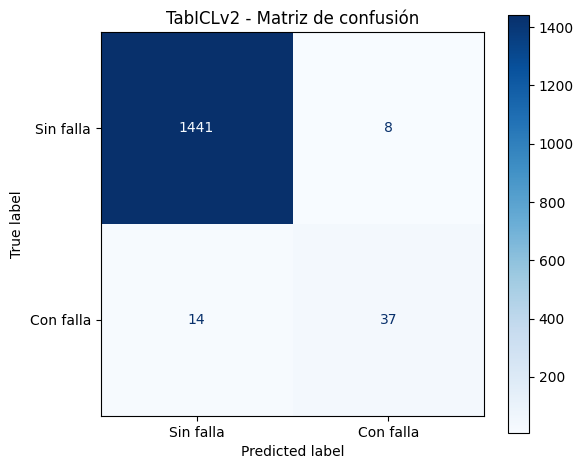


INTERPRETACIÓN OPERATIVA
Fallas detectadas correctamente: 37
Fallas no detectadas: 14
Falsas alarmas: 8
Operaciones normales correctamente clasificadas: 1441

EFICIENCIA
Tiempo total: 11.482 s
Latencia media amortizada: 7.655 ms/registro
Pico de memoria GPU: 669.65 MB


In [6]:
# BLOQUE 7 - EVALUACIÓN DE TABICLv2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Inferencia en lotes para controlar memoria
TAMANO_LOTE = 128

def predecir_por_lotes(modelo, datos, tamano_lote=128):
    probabilidades = []

    for inicio in range(0, len(datos), tamano_lote):
        lote = datos.iloc[inicio:inicio + tamano_lote]
        resultado = modelo.predict_proba(lote)
        probabilidades.append(resultado[:, 1])

    return np.concatenate(probabilidades)

# Calentamiento de la GPU/modelo
_ = modelo_tabicl.predict_proba(X_val_model.iloc[:8])
torch.cuda.synchronize()

# Reiniciar medición de memoria
torch.cuda.reset_peak_memory_stats()

# Medir exclusivamente inferencia
inicio = time.perf_counter()

prob_falla = predecir_por_lotes(
    modelo_tabicl,
    X_val_model,
    TAMANO_LOTE
)

torch.cuda.synchronize()
tiempo_inferencia = time.perf_counter() - inicio

# Clasificar con umbral inicial 0.50
umbral = 0.50
predicciones = (prob_falla >= umbral).astype(int)

# Métricas
accuracy = accuracy_score(y_val, predicciones)
precision = precision_score(
    y_val, predicciones, zero_division=0
)
recall = recall_score(
    y_val, predicciones, zero_division=0
)
f1 = f1_score(
    y_val, predicciones, zero_division=0
)
balanced_accuracy = balanced_accuracy_score(
    y_val, predicciones
)
avg_precision = average_precision_score(
    y_val, prob_falla
)

latencia_ms = (
    tiempo_inferencia / len(X_val_model) * 1000
)

memoria_gpu_mb = (
    torch.cuda.max_memory_allocated() / 1024**2
)

# Guardar resultados para la comparación posterior
resultado_tabicl = {
    "Modelo": "TabICLv2",
    "Conjunto": "Validación",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Balanced Accuracy": balanced_accuracy,
    "Average Precision": avg_precision,
    "Latencia ms/registro": latencia_ms,
    "Memoria GPU MB": memoria_gpu_mb,
    "Umbral": umbral
}

resultados_validacion = pd.DataFrame(
    [resultado_tabicl]
)

print("RESULTADOS DEL MODELO TABICLv2")
display(resultados_validacion.round(4))

# Matriz de confusión
matriz = confusion_matrix(
    y_val, predicciones, labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sin falla", "Con falla"]
).plot(ax=ax, cmap="Blues", values_format="d")

ax.set_title("TabICLv2 - Matriz de confusión")
plt.tight_layout()
plt.show()

# Interpretación operativa
tn, fp, fn, tp = matriz.ravel()

print("\nINTERPRETACIÓN OPERATIVA")
print("Fallas detectadas correctamente:", tp)
print("Fallas no detectadas:", fn)
print("Falsas alarmas:", fp)
print("Operaciones normales correctamente clasificadas:", tn)

print("\nEFICIENCIA")
print("Tiempo total:", round(tiempo_inferencia, 3), "s")
print("Latencia media amortizada:",
      round(latencia_ms, 3), "ms/registro")
print("Pico de memoria GPU:",
      round(memoria_gpu_mb, 2), "MB")
